ACCURACY RESULTS

IRIS DATASET (Linearly Separable):
  Manual Perceptron:       0.9667
  Scikit-learn Perceptron: 1.0000

MOONS DATASET (Not Linearly Separable):
  Manual Perceptron:       0.8667
  Scikit-learn Perceptron: 0.9333


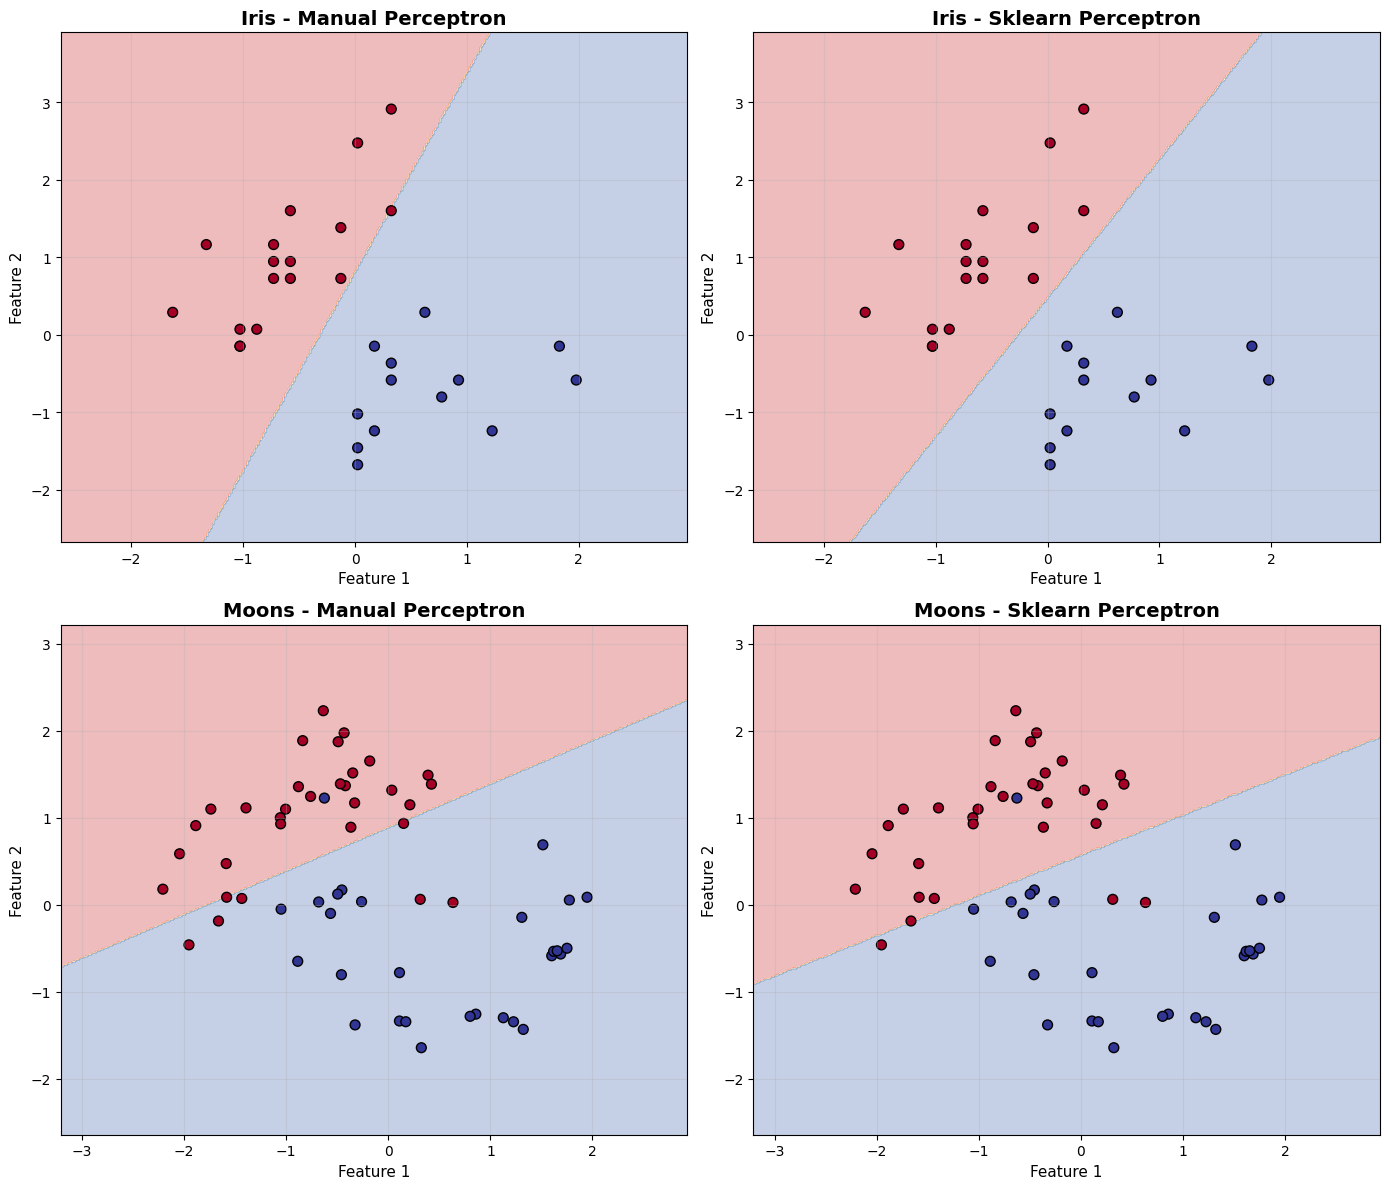

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

# Set random seed for reproducibility
np.random.seed(42)


# Load Iris dataset (2D, linearly separable)
iris = load_iris()
X_iris = iris.data[:100, :2]  # First 100 samples, first 2 features
y_iris = iris.target[:100]

# Create Make Moons dataset (2D, not linearly separable)
X_moons, y_moons = make_moons(n_samples=200, noise=0.15, random_state=42)

# Split datasets
X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.3, random_state=42
)

# Standardize features
scaler_iris = StandardScaler()
X_iris_train_scaled = scaler_iris.fit_transform(X_iris_train)
X_iris_test_scaled = scaler_iris.transform(X_iris_test)

scaler_moons = StandardScaler()
X_moons_train_scaled = scaler_moons.fit_transform(X_moons_train)
X_moons_test_scaled = scaler_moons.transform(X_moons_test)


class ManualPerceptron:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0

        for _ in range(self.n_iterations):
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = 1 if linear_output >= 0 else 0
                update = self.learning_rate * (y[idx] - y_predicted)
                self.weights += update * x_i
                self.bias += update

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        y_predicted = np.where(linear_output >= 0, 1, 0)
        return y_predicted


# Manual Perceptron on Iris
manual_perceptron_iris = ManualPerceptron(learning_rate=0.01, n_iterations=1000)
manual_perceptron_iris.fit(X_iris_train_scaled, y_iris_train)
y_pred_manual_iris = manual_perceptron_iris.predict(X_iris_test_scaled)

# Scikit-learn Perceptron on Iris
sklearn_perceptron_iris = Perceptron(max_iter=1000, random_state=42)
sklearn_perceptron_iris.fit(X_iris_train_scaled, y_iris_train)
y_pred_sklearn_iris = sklearn_perceptron_iris.predict(X_iris_test_scaled)

# Manual Perceptron on Moons
manual_perceptron_moons = ManualPerceptron(learning_rate=0.01, n_iterations=1000)
manual_perceptron_moons.fit(X_moons_train_scaled, y_moons_train)
y_pred_manual_moons = manual_perceptron_moons.predict(X_moons_test_scaled)

# Scikit-learn Perceptron on Moons
sklearn_perceptron_moons = Perceptron(max_iter=1000, random_state=42)
sklearn_perceptron_moons.fit(X_moons_train_scaled, y_moons_train)
y_pred_sklearn_moons = sklearn_perceptron_moons.predict(X_moons_test_scaled)


print("="*60)
print("ACCURACY RESULTS")
print("="*60)
print(f"\nIRIS DATASET (Linearly Separable):")
print(f"  Manual Perceptron:       {accuracy_score(y_iris_test, y_pred_manual_iris):.4f}")
print(f"  Scikit-learn Perceptron: {accuracy_score(y_iris_test, y_pred_sklearn_iris):.4f}")

print(f"\nMOONS DATASET (Not Linearly Separable):")
print(f"  Manual Perceptron:       {accuracy_score(y_moons_test, y_pred_manual_moons):.4f}")
print(f"  Scikit-learn Perceptron: {accuracy_score(y_moons_test, y_pred_sklearn_moons):.4f}")
print("="*60)


fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Helper function to plot decision boundary
def plot_decision_boundary(X, y, model, ax, title):
    h = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='RdYlBu', s=50)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Feature 1', fontsize=11)
    ax.set_ylabel('Feature 2', fontsize=11)
    ax.grid(True, alpha=0.3)

# Plot 1: Iris - Manual Perceptron
plot_decision_boundary(X_iris_test_scaled, y_iris_test, manual_perceptron_iris,
                       axes[0, 0], 'Iris - Manual Perceptron')

# Plot 2: Iris - Sklearn Perceptron
plot_decision_boundary(X_iris_test_scaled, y_iris_test, sklearn_perceptron_iris,
                       axes[0, 1], 'Iris - Sklearn Perceptron')

# Plot 3: Moons - Manual Perceptron
plot_decision_boundary(X_moons_test_scaled, y_moons_test, manual_perceptron_moons,
                       axes[1, 0], 'Moons - Manual Perceptron')

# Plot 4: Moons - Sklearn Perceptron
plot_decision_boundary(X_moons_test_scaled, y_moons_test, sklearn_perceptron_moons,
                       axes[1, 1], 'Moons - Sklearn Perceptron')

plt.tight_layout()
plt.show()

BREAST CANCER DATASET (30 Features - High Dimensional)

Dataset Shape: (569, 20)
Number of samples: 569
Number of features: 20
Classes: [0 1] (0=Malignant, 1=Benign)

ACCURACY RESULTS

Manual Perceptron Accuracy:       0.9415
Scikit-learn Perceptron Accuracy: 0.9649

FEATURE WEIGHTS ANALYSIS

--- MANUAL PERCEPTRON WEIGHTS ---
Bias: -0.210000

                Feature    Weight  Abs_Weight
             area error -1.209616    1.209616
         mean concavity -0.549806    0.549806
         mean perimeter  0.470532    0.470532
              mean area -0.435136    0.435136
       mean compactness  0.329923    0.329923
           radius error  0.299005    0.299005
        perimeter error  0.236346    0.236346
    mean concave points -0.177583    0.177583
        concavity error  0.150232    0.150232
      compactness error -0.124096    0.124096
        mean smoothness -0.112178    0.112178
           mean texture -0.100237    0.100237
fractal dimension error  0.088119    0.088119
 mean fract

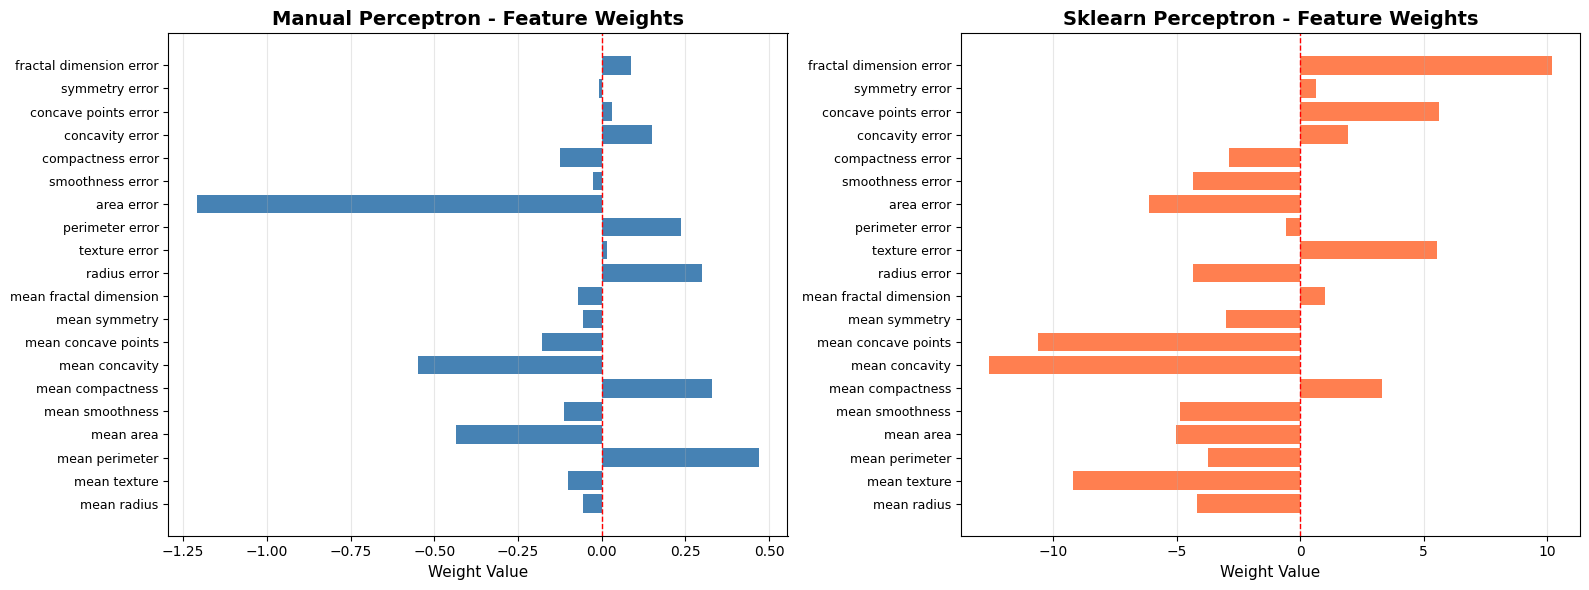


WEIGHT CORRELATION ANALYSIS

Correlation between Manual and Sklearn weights: 0.4419
Mean Absolute Weight Difference: 4.8644

Interpretation: Low correlation indicates different convergence paths,
which is common for non-convex optimization in high dimensions.

SUMMARY

Dataset: Breast Cancer (20 features, 569 samples)
Train/Test Split: 398/171 samples

Manual Perceptron Accuracy:       0.9415
Scikit-learn Perceptron Accuracy: 0.9649

Weight Correlation: 0.4419
Most Important Feature (Manual): area error
Most Important Feature (Sklearn): mean concavity


In [ ]:
# Import additional libraries
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

print("="*70)
print("BREAST CANCER DATASET (30 Features - High Dimensional)")
print("="*70)

#%% LOAD AND PREPARE BREAST CANCER DATASET

# Load breast cancer dataset
breast_cancer = load_breast_cancer()
X_cancer = breast_cancer.data[:, :20]  # Use first 20 features as requested
y_cancer = breast_cancer.target
feature_names = breast_cancer.feature_names[:20]

print(f"\nDataset Shape: {X_cancer.shape}")
print(f"Number of samples: {X_cancer.shape[0]}")
print(f"Number of features: {X_cancer.shape[1]}")
print(f"Classes: {np.unique(y_cancer)} (0=Malignant, 1=Benign)")

# Split dataset
X_cancer_train, X_cancer_test, y_cancer_train, y_cancer_test = train_test_split(
    X_cancer, y_cancer, test_size=0.3, random_state=42
)

# Standardize features
scaler_cancer = StandardScaler()
X_cancer_train_scaled = scaler_cancer.fit_transform(X_cancer_train)
X_cancer_test_scaled = scaler_cancer.transform(X_cancer_test)

#%% TRAIN MODELS ON BREAST CANCER DATASET

# Manual Perceptron
manual_perceptron_cancer = ManualPerceptron(learning_rate=0.01, n_iterations=1000)
manual_perceptron_cancer.fit(X_cancer_train_scaled, y_cancer_train)
y_pred_manual_cancer = manual_perceptron_cancer.predict(X_cancer_test_scaled)

# Scikit-learn Perceptron
sklearn_perceptron_cancer = Perceptron(max_iter=1000, random_state=42)
sklearn_perceptron_cancer.fit(X_cancer_train_scaled, y_cancer_train)
y_pred_sklearn_cancer = sklearn_perceptron_cancer.predict(X_cancer_test_scaled)

#%% PRINT ACCURACY RESULTS

print("\n" + "="*70)
print("ACCURACY RESULTS")
print("="*70)
print(f"\nManual Perceptron Accuracy:       {accuracy_score(y_cancer_test, y_pred_manual_cancer):.4f}")
print(f"Scikit-learn Perceptron Accuracy: {accuracy_score(y_cancer_test, y_pred_sklearn_cancer):.4f}")

#%% DISPLAY FEATURE WEIGHTS

print("\n" + "="*70)
print("FEATURE WEIGHTS ANALYSIS")
print("="*70)

# Create DataFrame for Manual Perceptron weights
manual_weights_df = pd.DataFrame({
    'Feature': feature_names,
    'Weight': manual_perceptron_cancer.weights
})
manual_weights_df['Abs_Weight'] = np.abs(manual_weights_df['Weight'])
manual_weights_df = manual_weights_df.sort_values('Abs_Weight', ascending=False)

print("\n--- MANUAL PERCEPTRON WEIGHTS ---")
print(f"Bias: {manual_perceptron_cancer.bias:.6f}\n")
print(manual_weights_df.to_string(index=False))

# Create DataFrame for Sklearn Perceptron weights
sklearn_weights_df = pd.DataFrame({
    'Feature': feature_names,
    'Weight': sklearn_perceptron_cancer.coef_[0]
})
sklearn_weights_df['Abs_Weight'] = np.abs(sklearn_weights_df['Weight'])
sklearn_weights_df = sklearn_weights_df.sort_values('Abs_Weight', ascending=False)

print("\n--- SCIKIT-LEARN PERCEPTRON WEIGHTS ---")
print(f"Bias: {sklearn_perceptron_cancer.intercept_[0]:.6f}\n")
print(sklearn_weights_df.to_string(index=False))

#%% TOP 5 MOST IMPORTANT FEATURES

print("\n" + "="*70)
print("TOP 5 MOST IMPORTANT FEATURES (by Absolute Weight)")
print("="*70)

print("\nManual Perceptron:")
print(manual_weights_df[['Feature', 'Weight']].head().to_string(index=False))

print("\nScikit-learn Perceptron:")
print(sklearn_weights_df[['Feature', 'Weight']].head().to_string(index=False))

#%% VISUALIZATION - FEATURE WEIGHTS COMPARISON

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Manual Perceptron weights
axes[0].barh(range(20), manual_perceptron_cancer.weights, color='steelblue')
axes[0].set_yticks(range(20))
axes[0].set_yticklabels(feature_names, fontsize=9)
axes[0].set_xlabel('Weight Value', fontsize=11)
axes[0].set_title('Manual Perceptron - Feature Weights', fontsize=14, fontweight='bold')
axes[0].axvline(x=0, color='red', linestyle='--', linewidth=1)
axes[0].grid(True, alpha=0.3, axis='x')

# Plot Sklearn Perceptron weights
axes[1].barh(range(20), sklearn_perceptron_cancer.coef_[0], color='coral')
axes[1].set_yticks(range(20))
axes[1].set_yticklabels(feature_names, fontsize=9)
axes[1].set_xlabel('Weight Value', fontsize=11)
axes[1].set_title('Sklearn Perceptron - Feature Weights', fontsize=14, fontweight='bold')
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=1)
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

#%% WEIGHT CORRELATION ANALYSIS

print("\n" + "="*70)
print("WEIGHT CORRELATION ANALYSIS")
print("="*70)

# Calculate correlation between manual and sklearn weights
weight_correlation = np.corrcoef(
    manual_perceptron_cancer.weights,
    sklearn_perceptron_cancer.coef_[0]
)[0, 1]

print(f"\nCorrelation between Manual and Sklearn weights: {weight_correlation:.4f}")

# Calculate mean absolute difference
mean_abs_diff = np.mean(np.abs(
    manual_perceptron_cancer.weights - sklearn_perceptron_cancer.coef_[0]
))

print(f"Mean Absolute Weight Difference: {mean_abs_diff:.4f}")

if weight_correlation > 0.9:
    print("\nInterpretation: High correlation indicates both implementations")
    print("learned very similar decision boundaries and feature importance.")
elif weight_correlation > 0.7:
    print("\nInterpretation: Moderate correlation indicates both implementations")
    print("learned similar patterns but with some differences in optimization.")
else:
    print("\nInterpretation: Low correlation indicates different convergence paths,")
    print("which is common for non-convex optimization in high dimensions.")

#%% SUMMARY

print("\n" + "="*70)
print("SUMMARY")
print("="*70)
print(f"\nDataset: Breast Cancer (20 features, {X_cancer.shape[0]} samples)")
print(f"Train/Test Split: {X_cancer_train.shape[0]}/{X_cancer_test.shape[0]} samples")
print(f"\nManual Perceptron Accuracy:       {accuracy_score(y_cancer_test, y_pred_manual_cancer):.4f}")
print(f"Scikit-learn Perceptron Accuracy: {accuracy_score(y_cancer_test, y_pred_sklearn_cancer):.4f}")
print(f"\nWeight Correlation: {weight_correlation:.4f}")
print(f"Most Important Feature (Manual): {manual_weights_df.iloc[0]['Feature']}")
print(f"Most Important Feature (Sklearn): {sklearn_weights_df.iloc[0]['Feature']}")
print("="*70)